# 01 · Synthetic series: can the models see structure that is really there?

Before spending compute on real markets, every model is tested on price series whose **true forecast distribution is known exactly**. That gives two things real data cannot:

- **A ceiling.** An *oracle* that knows the generating process issues the best possible forecast, so each model's score can be read as a share of what was achievable.
- **Unambiguous diagnosis.** If a model misses a trend, a mean reversion or a volatility regime here, it is the model, not noise in the data or a regime that never repeats.

Six scenarios cover the shapes that matter for trading signals: no structure, trends in both directions, mean reversion, volatility regimes and skewed jumps. On each, all predictors answer the same question, *where will the price be 5 observations from now?*, as probabilities on a shared threshold grid (see `sbench.forecast`):

- **11 decision models** served locally via `/v1/systemone`, each asked in **4 elicitation formats**, since how the question is asked turns out to change the answer;
- **TimesFM 3.0** and **TimesFM 2.5** (Google's time-series foundation models);
- **baselines**: zero-drift random walk (the bar to beat), empirical distribution of past changes, a constant 0.5.

The outcome is a shortlist of models and formats that go on to real assets in `02_real_assets`.

## Setup

In [1]:
import os
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from sbench import plots, tsfm
from sbench.backtest import decision_points, load_results, run_forecast_backtest
from sbench.elicitation import BinDistribution, DirectionChoice, DirectionNoul, ThresholdNoul
from sbench.forecast import make_task
from sbench.predictors import (
    ConstantPredictor,
    DecisionModelPredictor,
    EmpiricalPredictor,
    RandomWalkPredictor,
)
from sbench.scoring import per_forecast, reliability, skill_table, summary
from sbench.states import build_price_state
from sbench.synthetic import (
    JumpDiffusion,
    MeanReversion,
    OraclePredictor,
    RandomWalk,
    RegimeVolatility,
    synthetic_series,
    true_distribution,
)
from sbench.tsfm import QuantilePredictor, TimesFM3, TimesFM25

os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("HF_HUB_OFFLINE", "1")   # weights are cached; never re-check the Hub
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "data" / "results" / "01_synthetic" / "forecasts.csv"   # resumable; committed
CHARTS = ROOT / "outputs" / "01_synthetic"                                 # regenerated; not committed

HORIZON = 5            # forecast 5 observations ahead
N_OBS = 420            # observations per synthetic series
MIN_HISTORY = 100      # first decision point
MAX_POINTS = 60        # decision points per series (non-overlapping horizons)
STATE_LOOKBACK = 60    # rows of history shown to decision models

plots.use_style()
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## Models under test

All decision models are GGUF builds served locally through llama.cpp's `/v1/systemone` endpoint. They do not generate text: given a *state* and typed questions, each returns probabilities over the answer options in a single forward pass (`noul` = probability of yes, `score` = distribution over 2-10 ordered levels, `choice` = distribution over labelled options).

| Model | Params | Base model | Licence | Notes |
|---|---|---|---|---|
| [`julia-1`](https://huggingface.co/ggml-org/Julia-1-GGUF) | 0.1 B | mmBERT-small (ModernBERT family) | Apache 2.0 | smallest; multilingual |
| [`laya`](https://huggingface.co/ggml-org/Laya-GGUF) | 0.4 B | ModernBERT-large | Apache 2.0 | |
| [`d1-omni-600m`](https://huggingface.co/LiquidAI/d1-omni-600M-GGUF) | 0.6 B | LFM2.5-Encoder-350M (Liquid AI) | LFM Open License 1.0 | image and audio input |
| [`d1-3b`](https://huggingface.co/LiquidAI/d1-3B-GGUF) | 3 B | LFM2.5-VL-3B (Liquid AI) | LFM Open License 1.0 | image input |
| [`kev-4b`](https://huggingface.co/ggml-org/Kev-4B-GGUF) | 4 B | Qwen3.5-4B-Base | Apache 2.0 | |
| [`lev`](https://huggingface.co/ggml-org/lev-GGUF) | 4 B | Qwen3.5-4B | Apache 2.0 | |
| [`kev-9b`](https://huggingface.co/ggml-org/Kev-9B-GGUF) | 9 B | Qwen3.5-9B-Base | Apache 2.0 | |
| [`bespoke-nimble-9b-v3`](https://huggingface.co/ggml-org/Bespoke-Nimble-9B-v3-GGUF) | 9 B | Qwen3.5-9B | CC BY-NC 4.0 | non-commercial |
| [`cloudflare_clef-flash`](https://huggingface.co/bartowski/Cloudflare_clef-flash-GGUF) | 9 B | Qwen3.5-9B | Apache 2.0 | image input |
| [`openjev`](https://huggingface.co/ggml-org/OpenJev-GGUF) | 27 B | Qwen3.8-27B | CC BY-NC 4.0 | non-commercial; image input |
| [`clef`](https://huggingface.co/ggml-org/Clef-GGUF) | 27 B | Qwen3.8-27B | Apache 2.0 | image input |

Sources: the linked model cards and the llama.cpp [decision-models overview](https://huggingface.co/blog/ggml-org/decision-models-in-llamacpp).

**Time-series foundation models**: [TimesFM 3.0](https://huggingface.co/google/timesfm-3.0-pytorch) and its predecessor [TimesFM 2.5 (200M)](https://huggingface.co/google/timesfm-2.5-200m-pytorch), both run locally on GPU and both returning deciles of the value at the horizon. These are univariate scenarios, so TimesFM 3.0's covariate support is not used here.

## Scenarios

Each scenario is a daily price series simulated in log space from a process whose conditional distribution is available in closed form (`sbench.synthetic`). The decision models see only an anonymous label (*"Asset A: daily close price"*) and the last 60 closes, so nothing in the text gives the process away.

| Asset | Scenario | Daily log return | What a good forecaster should do |
|---|---|---|---|
| A | `random_walk` | N(0, 2%) | Nothing to exploit: match the random walk |
| B | `trend_up` | N(+0.6%, 1.5%) | Lean up, keep the spread |
| C | `trend_down` | N(−0.6%, 1.5%) | Lean down, keep the spread |
| D | `mean_reversion` | AR(1) in log price, φ = 0.8, σ = 2%, around the starting level | Lean back towards the level |
| E | `vol_regimes` | N(0, σ), σ switches between 0.8% (calm) and 4% (turbulent), Markov, mean stays of ~50 / ~33 days | Direction is a coin flip; widen or narrow the distribution with the regime |
| F | `jumps` | N(+0.3%, 0.8%) plus jumps (8% chance a day) of N(−5%, 3%) | Lean up most days but keep a fat left tail |

The structure is deliberately clear: a model that cannot find it here will not find subtler versions of it in real markets. Forecasts are made every 5 observations (non-overlapping horizons, so outcomes are independent), 60 per scenario.

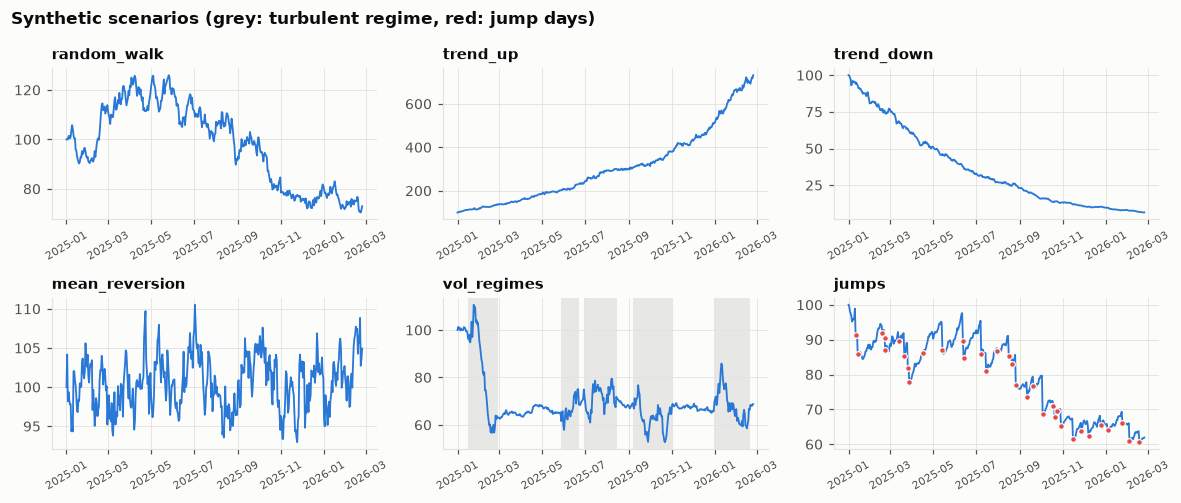

In [2]:
SCENARIOS = {
    "random_walk":    RandomWalk(mu=0.0, sigma=0.02),
    "trend_up":       RandomWalk(mu=0.006, sigma=0.015),
    "trend_down":     RandomWalk(mu=-0.006, sigma=0.015),
    "mean_reversion": MeanReversion(phi=0.8, sigma=0.02),
    "vol_regimes":    RegimeVolatility(sigma_calm=0.008, sigma_turbulent=0.04, stay_calm=0.98, stay_turbulent=0.97),
    "jumps":          JumpDiffusion(mu=0.003, sigma=0.008, jump_rate=0.08, jump_mean=-0.05, jump_std=0.03),
}
SERIES = [synthetic_series(key, proc, n=N_OBS, seed=i, description=f"Asset {chr(65 + i)}: daily close price")
          for i, (key, proc) in enumerate(SCENARIOS.items())]
IDXS = {s.key: decision_points(s, HORIZON, min_history=MIN_HISTORY, step=HORIZON, max_points=MAX_POINTS)
        for s in SERIES}

by_key = {s.key: s for s in SERIES}
plots.series_panels(
    SERIES,
    shade={"vol_regimes": by_key["vol_regimes"].meta["latent"] == 1},
    marks={"jumps": by_key["jumps"].meta["latent"] > 0},
    title="Synthetic scenarios (grey: turbulent regime, red: jump days)",
    path=CHARTS / "01_scenarios.png",
);

### The oracle

For every process the true distribution of the log price at the horizon, given all information up to the decision time, is a Gaussian mixture: a single Gaussian for the walks and the AR(1); a mixture over the number of turbulent days ahead for the regime model; a mixture over the number of jumps for the jump model. `OraclePredictor` evaluates it on the threshold grid. The regime oracle also knows the *current* regime, which other predictors have to infer from the price path, so it is a true upper bound.

The unit tests check the oracle against simulation (outcomes' PIT values are uniform for every process). The table shows how much the truth actually moves in each scenario: where P(up) never leaves 0.5, only the *shape* of the forecast can earn skill.

In [3]:
rows = []
for s in SERIES:
    for i in IDXS[s.key]:
        task = make_task(s, i, HORIZON)
        mix = true_distribution(task)
        lo, hi = np.exp(mix.ppf([0.1, 0.9]))
        rows.append({"scenario": s.key, "p_up": mix.sf(np.log(task.current))[0],
                     "band_80_pct": 100 * (hi - lo) / task.current})
truth = pd.DataFrame(rows).groupby("scenario", sort=False).agg(
    points=("p_up", "size"), p_up_mean=("p_up", "mean"), p_up_min=("p_up", "min"), p_up_max=("p_up", "max"),
    band_80_pct_median=("band_80_pct", "median"))
truth

,points,p_up_mean,p_up_min,p_up_max,band_80_pct_median
scenario,,,,,
random_walk,60,0.500,0.500,0.500,11.469
trend_up,60,0.814,0.814,0.814,8.861
trend_down,60,0.186,0.186,0.186,8.345
mean_reversion,60,0.445,0.056,0.885,8.031
vol_regimes,60,0.500,0.500,0.500,21.946
jumps,60,0.580,0.580,0.580,9.623


## How the decision models are asked

Every decision model receives the same state (anonymous label, decision date, current close and the last 60 closes) and is asked in four formats (`sbench.elicitation`):

| Format | Questions | Output |
|---|---|---|
| `threshold_noul` | one yes/no per threshold: *"Will the close price 5 daily observations from now be strictly above X?"* | full distribution (9 thresholds) |
| `bin_score` | one `score` question whose 10 ordered levels are the ranges between thresholds | full distribution, coherent by construction |
| `direction_noul` | one yes/no: above the current value? | P(up) only |
| `direction_choice` | higher / lower (no "unchanged" option: on a continuous price it would only soak up probability) | P(up) only |

Thresholds sit at 0, ±0.5, ±1, ±1.5 and ±2 recent-volatility units around the current value, the same grid every predictor answers on. An example for one decision point:

In [4]:
STATE = partial(build_price_state, lookback=STATE_LOOKBACK)
ELICITATIONS = [ThresholdNoul(), BinDistribution("score"), DirectionNoul(), DirectionChoice(include_flat=False)]

example = make_task(SERIES[1], IDXS[SERIES[1].key][0], HORIZON)
lines = STATE(example).splitlines()
print("\n".join(lines[:6] + ["  ..."] + lines[-2:]))
print()
for el in ELICITATIONS:
    q = next(iter(el.questions(example).values()))
    extra = f"  levels: {q['criteria'][:2]} ... {q['criteria'][-1:]}" if q["type"] == "score" else (
        f"  options: {q['criteria']}" if q["type"] == "choice" else "")
    print(f"{el.name:17s} [{q['type']}] {q['instructions']}{extra}")

Asset B: daily close price
Decision time: 2025-04-11
Current close price: 163.16 USD
History (oldest → newest):
  2025-02-11: 125.77 USD
  2025-02-12: 125.24 USD
  ...
  2025-04-10: 161.38 USD
  2025-04-11: 163.16 USD

threshold_noul    [noul] Will the close price 5 daily observations from now be strictly above 153.88 USD?
bin_score         [score] Where will the close price be 5 daily observations from now?  levels: ['at or below 153.88 USD', 'above 153.88 USD and at most 156.15 USD'] ... ['above 173.01 USD']
direction_noul    [noul] Will the close price 5 daily observations from now be strictly above the current 163.16 USD?
direction_choice  [choice] Compared with now, where will the close price be 5 daily observations from now?  options: {'up': 'Higher than now', 'down': 'Lower than now'}


## Running the backtest

Every predictor answers every decision point; results are appended to a long-format CSV after each forecast, so the run can be interrupted and resumed (`sbench.backtest`). A model the server cannot serve is reported and skipped, and fills in on a later run once it can be. Warm decision-model latency ranges from about 0.1 s (laya, one question) to 4 s (clef, nine questions) per forecast, so the full grid takes a few hours; TimesFM takes about 0.2 s per forecast on GPU.

In [5]:
MODELS = ["julia-1", "laya", "d1-omni-600m", "d1-3b", "kev-4b", "lev", "kev-9b", "bespoke-nimble-9b-v3",
          "cloudflare_clef-flash", "openjev", "clef"]

REFERENCE = [
    OraclePredictor(),
    RandomWalkPredictor(),
    EmpiricalPredictor(),
    ConstantPredictor(),
    QuantilePredictor(TimesFM3(), name="timesfm3", log_space=True),
    QuantilePredictor(TimesFM25(), name="timesfm2.5", log_space=True),
]


def available(model: str) -> bool:
    # One full-size request (largest state, nine questions) before committing hours to a model.
    try:
        DecisionModelPredictor(model, ThresholdNoul(), STATE).predict(example)
        return True
    except Exception as e:  # noqa: BLE001 -- reported, model skipped
        print(f"{model}: unavailable, skipped ({str(e).splitlines()[0][:160]})")
        return False


SERVED = [m for m in MODELS if available(m)]
DECISION = [DecisionModelPredictor(m, el, STATE) for m in SERVED for el in ELICITATIONS]
print(f"{len(SERVED)}/{len(MODELS)} decision models available: {', '.join(SERVED)}")

11/11 decision models available: julia-1, laya, d1-omni-600m, d1-3b, kev-4b, lev, kev-9b, bespoke-nimble-9b-v3, cloudflare_clef-flash, openjev, clef


In [6]:
# Model-outer loop: the server loads each decision model once rather than once per scenario.
GROUPS = [REFERENCE] + [[p for p in DECISION if p.model == m] for m in SERVED]
for preds in GROUPS:
    for s in SERIES:
        run_forecast_backtest(s, preds, HORIZON, RESULTS, IDXS[s.key], verbose=False)
    if preds is REFERENCE:
        tsfm.release()   # TimesFM would otherwise hold ~2.4 GB of GPU memory the server needs

results = load_results(RESULTS)
results = results[results["series"].isin(SCENARIOS) & (results["horizon"] == HORIZON)].reset_index(drop=True)

coverage = results.groupby(["predictor", "series"])["t"].nunique().unstack()
print(f"{results['predictor'].nunique()} predictors; decision points answered per scenario "
      f"(expected {MAX_POINTS}): min {coverage.min().min()}, max {coverage.max().max()}")

50 predictors; decision points answered per scenario (expected 60): min 60, max 60


## Results

Scores are computed per forecast (`sbench.scoring.per_forecast`) and compared with the random walk on the decision points both answered:

- **CRPS skill** (full-distribution forecasts only): 1 − CRPS / CRPS of the random walk. Positive means a better *distribution* than the random walk; the oracle shows how much was achievable.
- **Brier skill on P(up)**: the same idea for the direction alone, available for all four formats.
- `lo`, `hi`: 95% paired bootstrap interval of the skill over decision points; an interval entirely above 0 means reliably better than the random walk.

The direction formats return P(up) only, so they have no CRPS, coverage or threshold coherence and get a table of their own. The random walk is the baseline (skill 0 by definition) and is not listed.

In [7]:
REFS = {"oracle", "random_walk", "empirical", "constant"}


def group(name: str) -> str:
    if name == "oracle":
        return "oracle"
    if name.startswith("timesfm"):
        return "foundation model"
    return "baseline" if name in REFS else "decision model"


def skill_cols(df: pd.DataFrame, metric: str, label: str) -> pd.DataFrame:
    sk = skill_table(df, metric).set_index("predictor")
    return sk[["N", "skill", "lo", "hi"]].rename(columns=lambda c: c if c == "N" else f"{label}_{c}")


per = per_forecast(results)
per["model"] = per["predictor"].str.split("/").str[0]
per["format"] = per["predictor"].str.split("/").str[1].fillna("-")
per["group"] = per["predictor"].map(group)

full = per[per["crps_n"].notna()]
direction_only = per.loc[per["format"].str.startswith("direction"), "predictor"].unique()
pooled = summary(per, by=("horizon",), ci=False).loc[HORIZON]
brier_up = skill_cols(per, "brier_up", "brier_up")

display(Markdown("**Full distributions** (threshold and bin formats, TimesFM, baselines)"))
display(skill_cols(full, "crps_n", "crps")
        .join(brier_up.drop(columns="N"))
        .join(pooled[["cover_80", "coherence", "p_spread"]])
        .sort_values("crps_skill", ascending=False))
display(Markdown("**Direction only** (P(up) formats)"))
display(brier_up.loc[direction_only].sort_values("brier_up_skill", ascending=False))

**Full distributions** (threshold and bin formats, TimesFM, baselines)

,N,crps_skill,crps_lo,crps_hi,brier_up_skill,brier_up_lo,brier_up_hi,cover_80,coherence,p_spread
predictor,,,,,,,,,,
oracle,360,0.137,0.092,0.178,0.185,0.115,0.255,0.822,0.000,0.910
timesfm3,360,0.110,0.061,0.155,0.157,0.078,0.231,0.792,0.000,0.942
timesfm2.5,360,0.105,0.069,0.142,0.144,0.087,0.203,0.836,0.000,0.911
empirical,360,0.093,0.046,0.138,0.136,0.063,0.203,0.781,0.000,0.917
clef/threshold_noul,360,0.017,-0.008,0.042,0.055,0.012,0.097,0.814,0.028,0.869
clef/bin_score,360,0.003,-0.029,0.034,0.069,0.005,0.129,0.578,0.000,0.966
openjev/bin_score,360,-0.010,-0.056,0.037,-0.126,-0.250,-0.009,0.553,0.000,0.967
kev-9b/threshold_noul,360,-0.015,-0.047,0.016,-0.012,-0.072,0.044,0.894,0.023,0.775
openjev/threshold_noul,360,-0.026,-0.067,0.014,-0.024,-0.130,0.085,0.464,0.004,0.948


**Direction only** (P(up) formats)

,N,brier_up_skill,brier_up_lo,brier_up_hi
predictor,,,,
lev/direction_choice,360,0.062,0.002,0.119
d1-3b/direction_choice,360,0.034,-0.023,0.093
openjev/direction_noul,360,0.014,-0.099,0.125
d1-omni-600m/direction_choice,360,0.010,-0.017,0.037
d1-omni-600m/direction_noul,360,-0.004,-0.046,0.039
bespoke-nimble-9b-v3/direction_choice,360,-0.007,-0.100,0.083
kev-9b/direction_noul,360,-0.007,-0.074,0.064
openjev/direction_choice,360,-0.014,-0.115,0.084
clef/direction_noul,360,-0.037,-0.152,0.072


### Full distributions: who gets closest to the oracle?

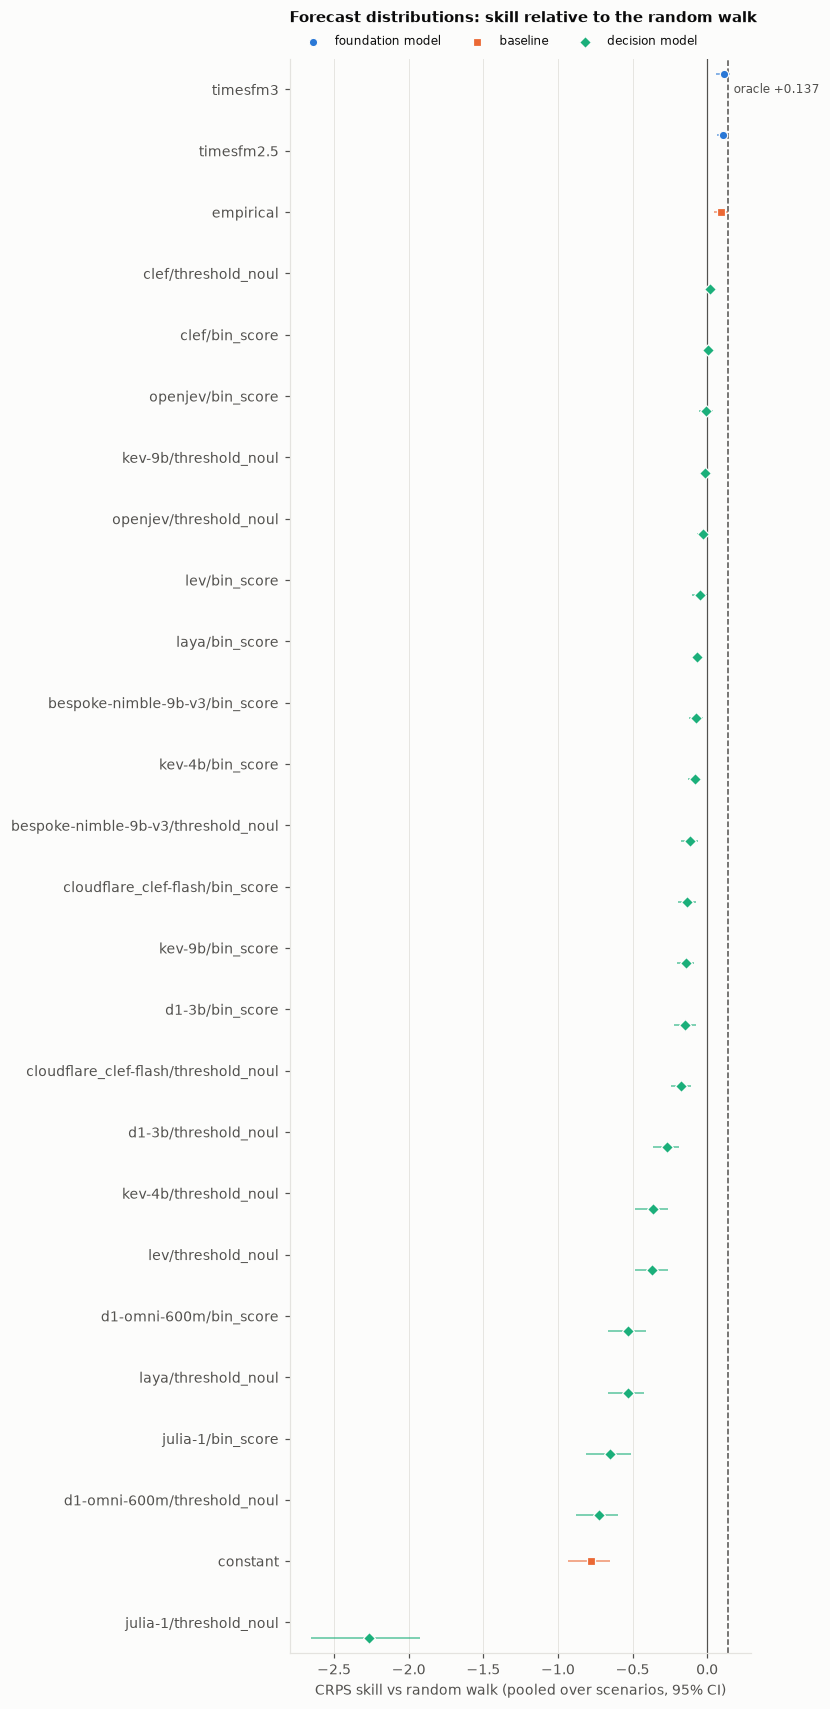

In [8]:
sk = skill_table(full, "crps_n").merge(per[["predictor", "group"]].drop_duplicates(), on="predictor")
oracle_skill = sk.loc[sk["predictor"] == "oracle", "skill"].iloc[0]
sk = sk[sk["predictor"] != "oracle"].sort_values("skill", ascending=False)

fig = plots.dot_plot(sk, y="predictor", x="skill", hue="group", lo="lo", hi="hi",
                     xlabel="CRPS skill vs random walk (pooled over scenarios, 95% CI)",
                     title="Forecast distributions: skill relative to the random walk")
ax = fig.axes[0]
ax.axvline(oracle_skill, color=plots.INK_2, lw=1, ls="--")
ax.annotate(f"oracle {oracle_skill:+.3f}", (oracle_skill, 0), xytext=(4, 0), textcoords="offset points",
            fontsize=8, color=plots.INK_2, va="center")
fig.savefig(CHARTS / "02_crps_skill.png");

### By scenario

Pooled scores can hide a model that is good in one scenario and bad in another. Each cell is CRPS skill vs the random walk on that scenario's 60 decision points (blue = better than the random walk, red = worse). Colours are capped at ±1 so the smaller differences stay visible; the numbers are not.

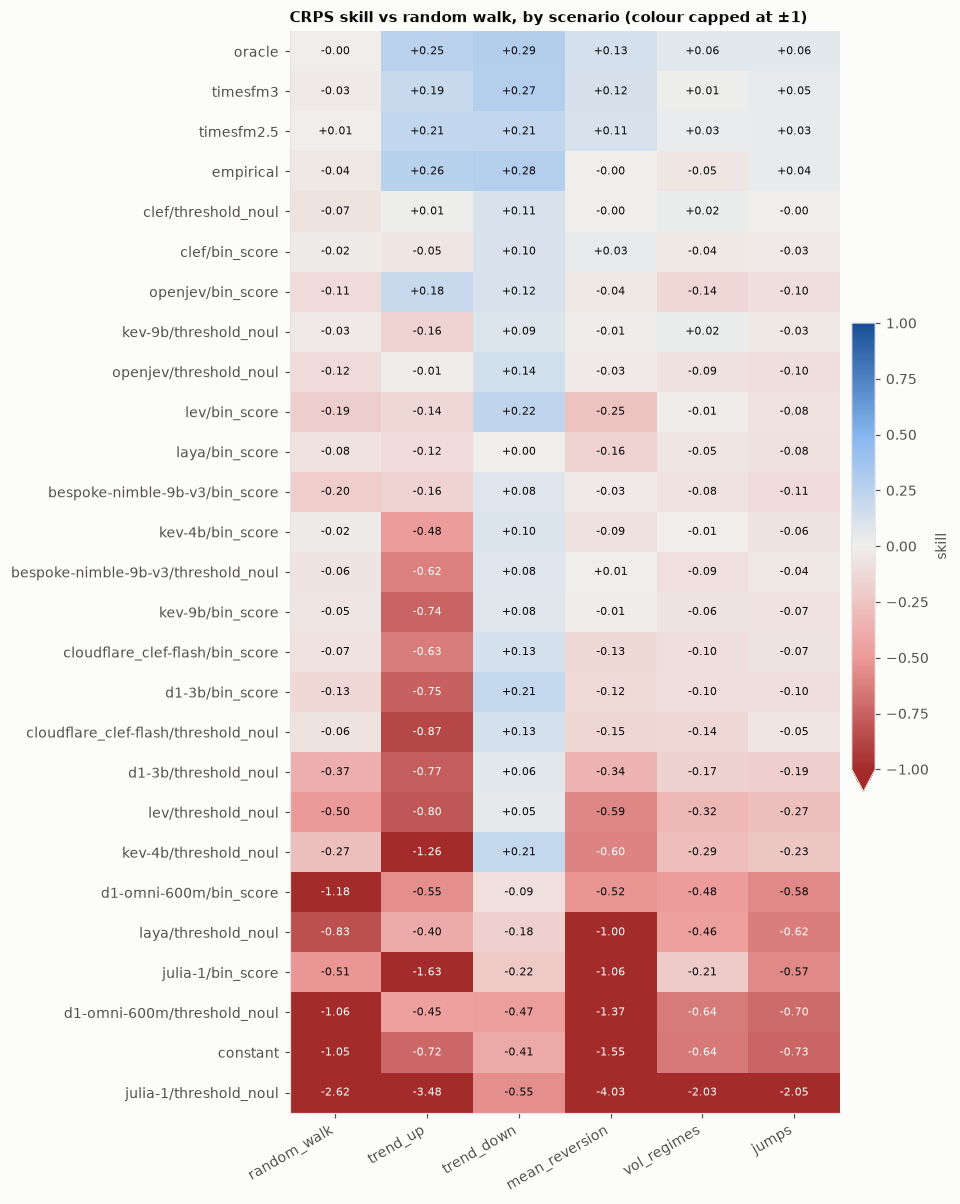

In [9]:
by_sc = skill_table(full, "crps_n", by=("series",)).pivot(index="predictor", columns="series", values="skill")
by_sc = by_sc[list(SCENARIOS)]
order = ["oracle"] + [p for p in by_sc.mean(axis=1).sort_values(ascending=False).index if p != "oracle"]
plots.heatmap(by_sc.loc[order], span=1, title="CRPS skill vs random walk, by scenario (colour capped at ±1)",
              cbar_label="skill", path=CHARTS / "03_crps_skill_by_scenario.png");

### Direction: does the question format matter?

All four formats yield P(up), so they can be compared head to head. Brier skill on P(up) vs the random walk, pooled over the four scenarios where the true P(up) actually moves (in `random_walk` and `vol_regimes` it is always 0.5, so any lean there can only cost).

Reference Brier skill on the same points: `oracle` +0.278, `empirical` +0.224, `constant` +0.000, `timesfm3` +0.251, `timesfm2.5` +0.219

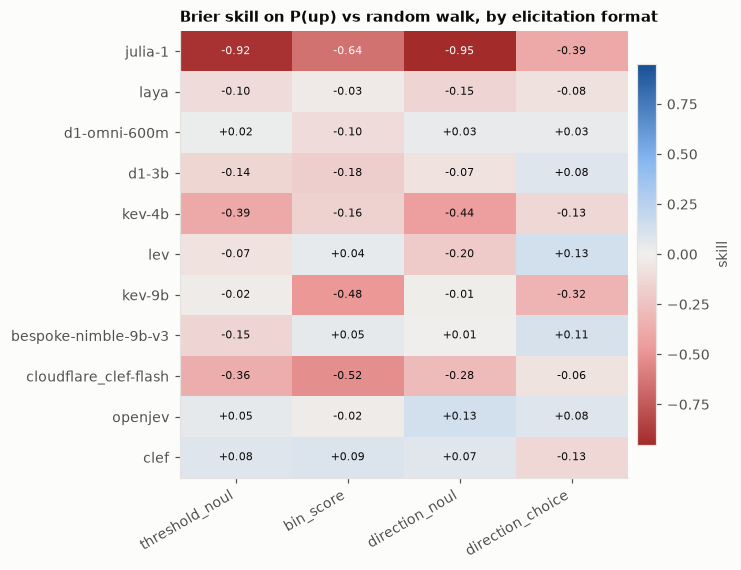

In [10]:
DIRECTIONAL = ["trend_up", "trend_down", "mean_reversion", "jumps"]
dir_per = per[per["series"].isin(DIRECTIONAL)]
dsk = skill_table(dir_per, "brier_up").merge(per[["predictor", "model", "format"]].drop_duplicates(), on="predictor")
fmt = dsk[dsk["format"] != "-"].pivot(index="model", columns="format", values="skill")
fmt = fmt.reindex(columns=[e.name for e in ELICITATIONS]).loc[[m for m in SERVED if m in fmt.index]]
refs = dsk[dsk["format"] == "-"].set_index("predictor")["skill"]
display(Markdown("Reference Brier skill on the same points: " + ", ".join(f"`{k}` {v:+.3f}" for k, v in refs.items())))
plots.heatmap(fmt, title="Brier skill on P(up) vs random walk, by elicitation format",
              cbar_label="skill", path=CHARTS / "04_format_comparison.png");

### Do the answers track the truth?

Skill scores mix two things: whether a model's P(up) *moves with* the true probability, and whether its level is right. Plotting each model's P(up) against the oracle's separates them. Each panel shows one model in its best format by Brier skill; `r` is the correlation with the oracle.

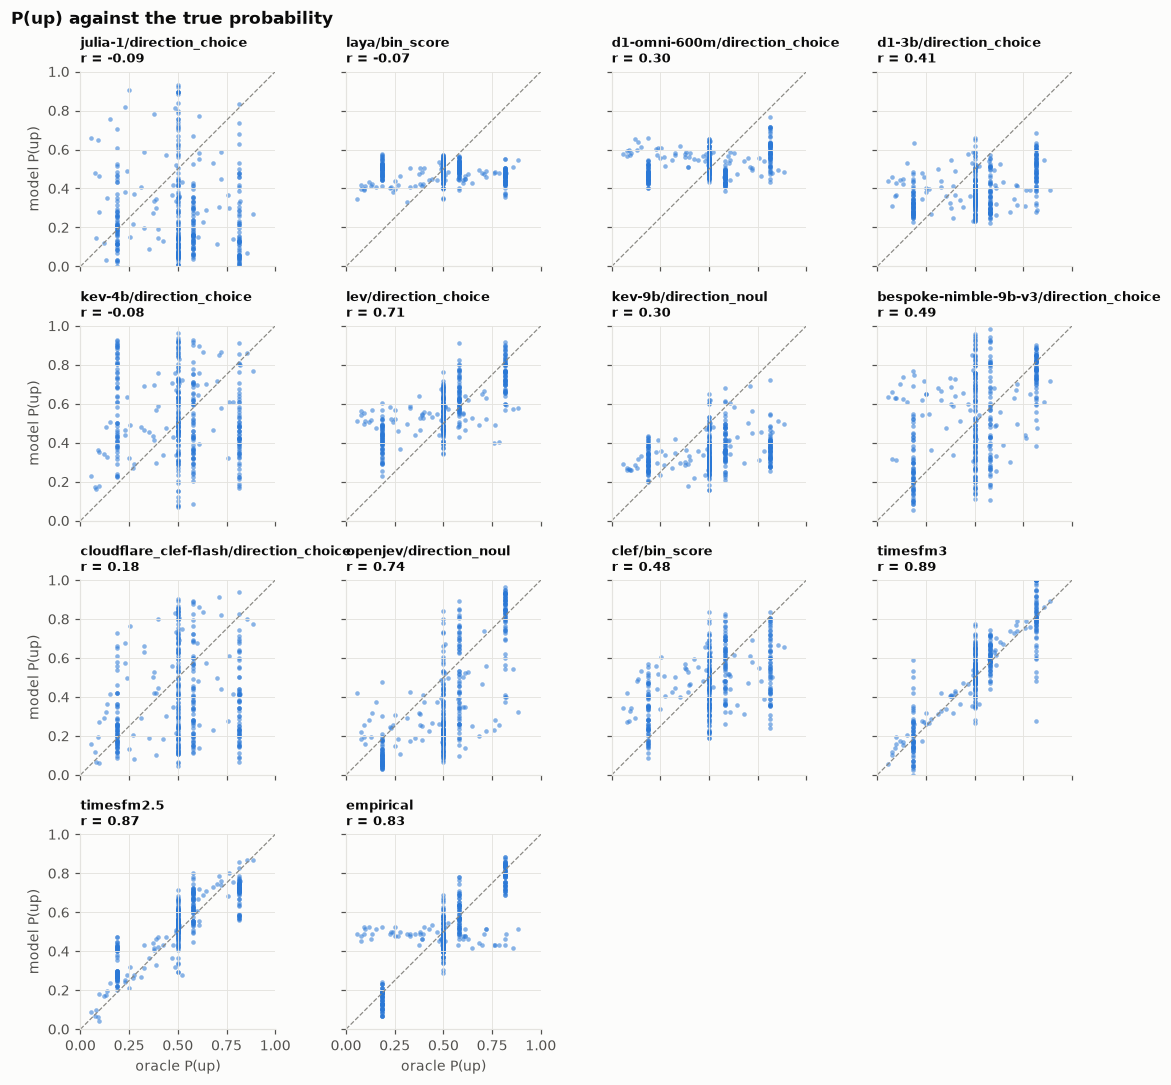

In [11]:
best_fmt = fmt.idxmax(axis=1)
best = [f"{m}/{f}" for m, f in best_fmt.items()]
oracle_up = per[per["predictor"] == "oracle"][["series", "t", "p_up"]].rename(columns={"p_up": "oracle_p_up"})
track = per[per["predictor"].isin(best + ["timesfm3", "timesfm2.5", "empirical"])].merge(oracle_up, on=["series", "t"])
plots.scatter_panels(track, "predictor", x="oracle_p_up", y="p_up", order=best + ["timesfm3", "timesfm2.5", "empirical"],
                     xlabel="oracle P(up)", ylabel="model P(up)", title="P(up) against the true probability",
                     path=CHARTS / "05_p_up_vs_oracle.png");

### Calibration of the full distributions

Reliability of every threshold answer (all nine thresholds, all scenarios): when a model says 30%, does the price end up above the threshold 30% of the time? Points on the diagonal are calibrated; dot area is the number of answers. Shown for each model's better full-distribution format.

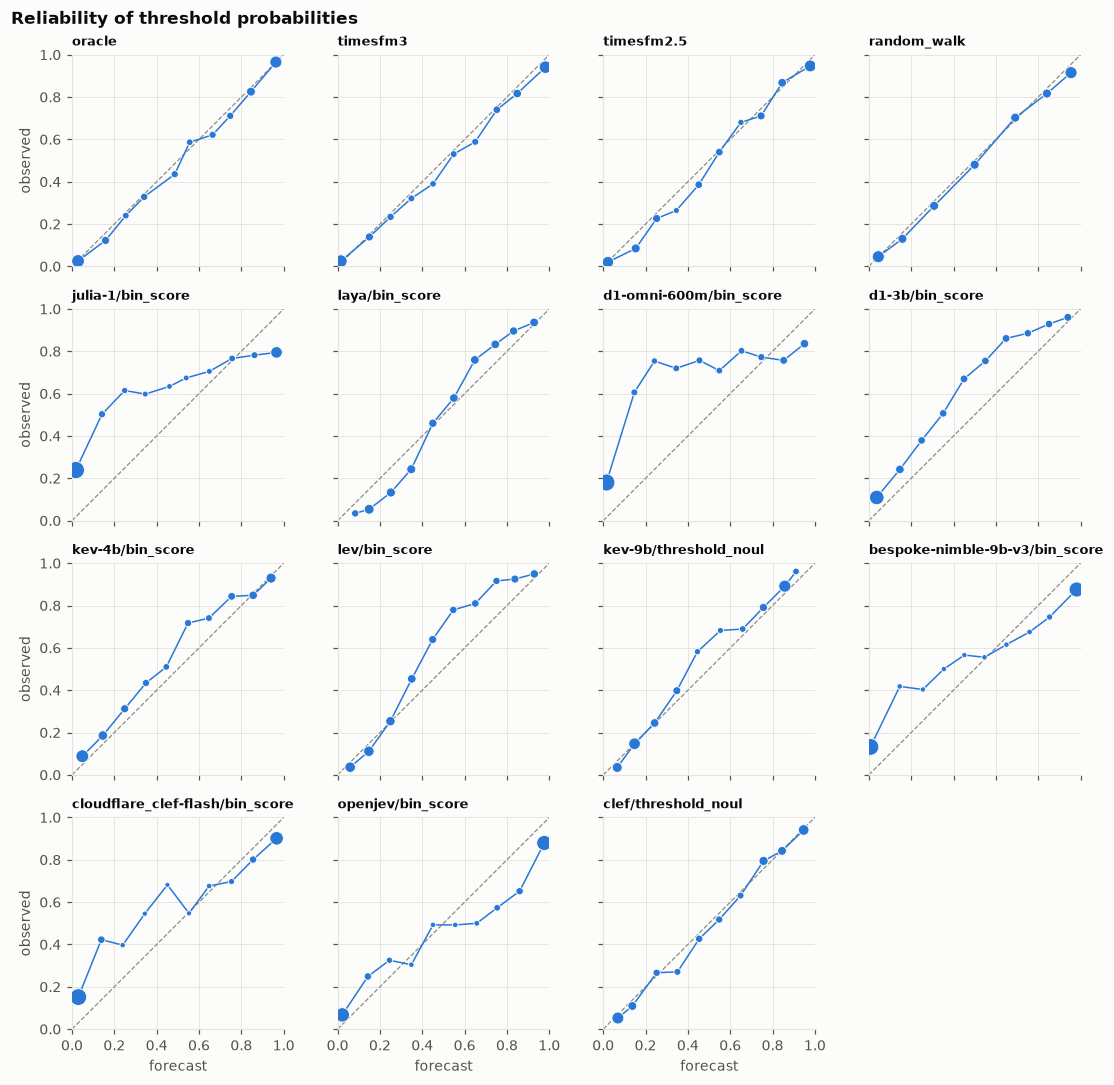

In [12]:
full_sk = skill_table(full, "crps_n").merge(per[["predictor", "model", "format"]].drop_duplicates(), on="predictor")
best_full = (full_sk[full_sk["format"] != "-"].sort_values("skill", ascending=False)
             .drop_duplicates("model").set_index("model").loc[[m for m in SERVED if m in set(full_sk["model"])]]["predictor"].tolist())
panel = ["oracle", "timesfm3", "timesfm2.5", "random_walk"] + best_full
rel = reliability(results[results["predictor"].isin(panel)])
plots.reliability_panels(rel, order=panel, title="Reliability of threshold probabilities",
                         path=CHARTS / "06_reliability.png");

### Agreement between predictors

Ensembles and agreement filters (planned for `04_combinations`) only help if models make *different* errors. Correlation of P(up) across decision points, for each model's best direction format and the reference predictors:

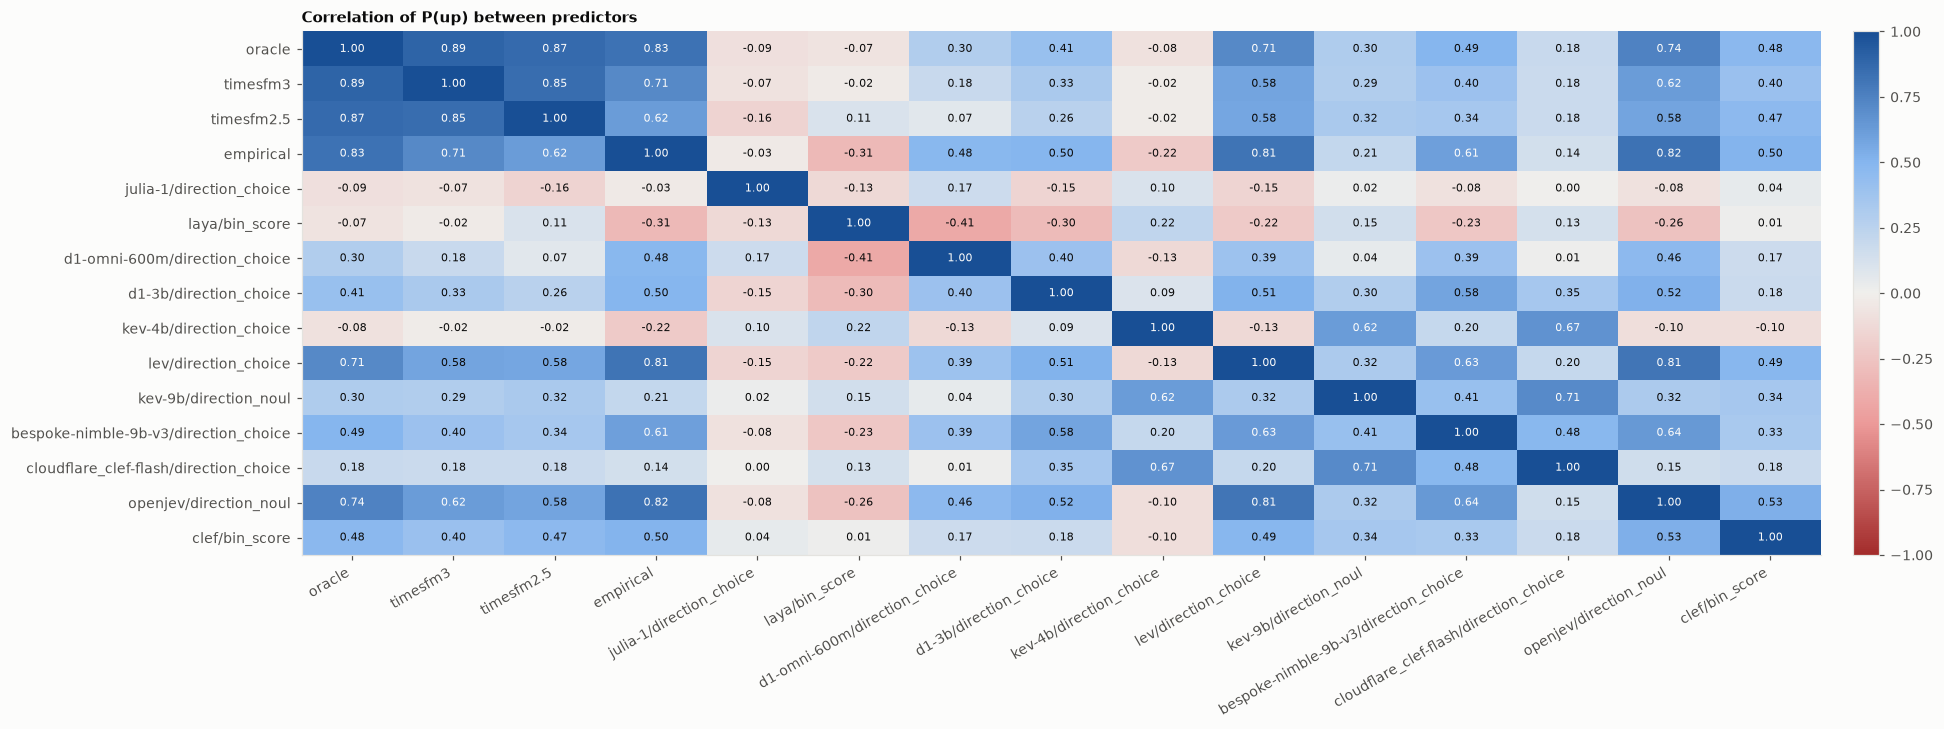

In [13]:
agree = per[per["predictor"].isin(best + ["oracle", "timesfm3", "timesfm2.5", "empirical"])]
corr = agree.pivot_table(index=["series", "t"], columns="predictor", values="p_up").corr()
order = ["oracle", "timesfm3", "timesfm2.5", "empirical"] + best
plots.heatmap(corr.loc[order, order], center=0, span=1, fmt="{:.2f}", title="Correlation of P(up) between predictors",
              path=CHARTS / "07_agreement.png");

### Which way do the models lean?

The pooled correlations above mostly measure whether a model tells the trend scenarios apart. Two sharper checks on the same predictors:

- `bias_*`: the average gap between the model's P(up) and the true P(up) in each trend scenario, and over all scenarios (negative = too bearish).
- `r_mean_reversion`: the correlation with the true P(up) *within* `mean_reversion`, the only scenario where the truth changes from one decision point to the next.

In [14]:
shown = best + ["timesfm3", "timesfm2.5", "empirical"]
lean = per[per["predictor"].isin(shown)].merge(oracle_up, on=["series", "t"])
lean["bias"] = lean["p_up"] - lean["oracle_p_up"]
mr = lean[lean["series"] == "mean_reversion"]
pd.DataFrame({
    "bias_trend_up": lean[lean["series"] == "trend_up"].groupby("predictor")["bias"].mean(),
    "bias_trend_down": lean[lean["series"] == "trend_down"].groupby("predictor")["bias"].mean(),
    "bias_all": lean.groupby("predictor")["bias"].mean(),
    "r_mean_reversion": mr.groupby("predictor")[["p_up", "oracle_p_up"]].apply(lambda g: g["p_up"].corr(g["oracle_p_up"])),
}).loc[shown]

,bias_trend_up,bias_trend_down,bias_all,r_mean_reversion
predictor,,,,
julia-1/direction_choice,-0.605,0.042,-0.231,-0.164
laya/bin_score,-0.358,0.316,-0.020,0.650
d1-omni-600m/direction_choice,-0.219,0.286,0.017,-0.637
d1-3b/direction_choice,-0.309,0.136,-0.110,-0.079
kev-4b/direction_choice,-0.369,0.419,0.024,0.689
lev/direction_choice,-0.054,0.228,0.072,0.211
kev-9b/direction_noul,-0.447,0.128,-0.147,0.623
bespoke-nimble-9b-v3/direction_choice,-0.047,0.097,0.029,-0.159
cloudflare_clef-flash/direction_choice,-0.456,0.081,-0.105,0.443


## Conclusions

#### The test bed works.
The oracle is the clear winner (CRPS skill +0.137, 95% interval 0.092 to 0.178) and ties the random walk on `random_walk` (−0.00), where nothing can be exploited; the random walk's own reliability curve lies on the diagonal. Differences between predictors therefore come from the predictors, not from the scoring.

#### 1. TimesFM recovers about 80% of the achievable skill
CRPS skill is +0.110 for TimesFM 3.0 and +0.105 for 2.5, both calibrated (80% intervals cover 79% and 84% of outcomes), and TimesFM 3.0's P(up) correlates 0.89 with the true one. Pooled, both overlap the `empirical` baseline (+0.093); the difference shows by scenario. On `mean_reversion` TimesFM scores +0.12 / +0.11 against the oracle's +0.13, while `empirical` scores −0.00 because it extrapolates past drift (within-scenario correlation with the truth 0.98 vs −0.40). The gap that remains is in `vol_regimes` (+0.01 / +0.03 vs +0.06): TimesFM is slow to widen its distribution when the regime turns. TimesFM 3.0 and 2.5 cannot be told apart on this data.

#### 2. No decision model beats the random walk on full distributions.
The best is clef with `threshold_noul` at +0.017 (interval −0.008 to +0.042), and none reaches the `empirical` baseline. On direction alone three combinations clear zero, all narrowly: clef `bin_score` (+0.069), clef `threshold_noul` (+0.055) and lev `direction_choice` (+0.062, interval from +0.002), against +0.157 for TimesFM 3.0. With 44 model/format combinations tested, two or three narrow hits at the 95% level are roughly what chance alone produces, so these are candidates to test on real data, not findings.

#### 3. The decision models fade the move.
In their best direction format, 10 of 11 models put P(up) below the truth in `trend_up` (by up to 0.6) and 10 of 11 above it in `trend_down`: they expect steady trends to reverse. The same prior helps where reversal is real: within `mean_reversion`, kev-4b, laya and kev-9b track the true P(up) with correlations of 0.62 to 0.69, where `empirical` is negative. In the full-distribution formats most models also lean bearish overall: their reliability curves sit above the diagonal, i.e. prices end above the thresholds more often than they predict. Short-horizon reversal does exist in real markets, so this prior may look better on real data than here; `02_real_assets` should test it explicitly rather than assume it away.

#### 4. The elicitation format matters as much as the model, with no format best for all
On the directional scenarios kev-9b's Brier skill ranges from −0.01 (`direction_noul`) to −0.48 (`bin_score`), lev's from −0.20 (`direction_noul`) to +0.13 (`direction_choice`). The pilot observation that value ranges raise kev-9b's P(up) does not hold over 360 points (mean P(up) 0.21 with `bin_score` vs 0.38 with `threshold_noul`). Formats are therefore fixed per model here, on synthetic data, so that `02_real_assets` does not choose them on real outcomes.

#### 5. Calibration tends to split by size
The larger models are overconfident: openjev, bespoke-nimble-9b-v3 and cloudflare_clef-flash in both formats, and kev-9b with `bin_score`, have 80% intervals that cover only 41–58% of outcomes. laya and d1-omni-600m are too vague with `threshold_noul`: their 80% intervals cover 94% of outcomes, as the constant 0.5 forecast does. Only clef `threshold_noul` (80% coverage 0.81, reliability on the diagonal) and kev-9b `threshold_noul` (0.89) are close to calibrated.

#### 6. The small encoders barely work on this task.
julia-1 saturates (P(up) 0.02 everywhere with `threshold_noul`, a spread of 0.03 across nine thresholds). With `threshold_noul` laya is flat (spread 0.41) and incoherent (its P(above) climbs back up by 0.39 per forecast on average, where it should only fall), and d1-omni-600m's spread (0.14) is barely above the constant forecast's. They are the fastest models, but apart from laya's `bin_score` answers following mean reversion they carry little usable information here.

#### 7. Size helps, unevenly.
The two 27B models (clef, openjev) are the best decision models. 9B beats 4B with `threshold_noul` (kev-9b −0.015 vs kev-4b −0.365) but not with `bin_score`, and the 9B cloudflare_clef-flash is among the worst on `trend_up` (CRPS skill −0.63 and −0.87).

#### 8. Agreement limits ensembling.
The kev-4b, kev-9b and cloudflare_clef-flash answers correlate 0.62–0.71 with each other but weakly with the truth, so they share their errors. The best direction answers of lev and openjev correlate 0.81–0.82 with `empirical`: much of what they get right is trend extrapolation that a free baseline already provides.

### Going to `02_real_assets`

| Predictor | Format | Role |
|---|---|---|
| TimesFM 3.0 | deciles | main forecaster |
| TimesFM 2.5 | deciles | previous-generation reference |
| `random_walk`, `empirical` | — | baselines: the bar to beat, and trend extrapolation for free |
| clef | `threshold_noul` | best decision model on distributions and direction; calibrated |
| kev-9b | `threshold_noul` | calibrated; tracks mean reversion |
| lev | `direction_choice` | only direction format with an interval above 0; 4B and fast |
| openjev | `direction_noul` | upper reference for direction (correlation 0.74 with the truth); 27B and CC BY-NC, so a reference only and not a candidate for distillation |

Dropped: julia-1, laya and d1-omni-600m (little or no signal), cloudflare_clef-flash (overconfident and against the trend), bespoke-nimble-9b-v3 (overconfident; CC BY-NC), kev-4b and d1-3b (dominated by kev-9b and lev).

### Caveats

- 60 decision points per scenario and 44 decision-model combinations: single narrow wins should be read as hypotheses.
- One state template (anonymous label, last 60 closes). Other states, such as indicators or context, may change the picture; that is the subject of `03_enrichment`.
- The decision models are not built as forecasters, and this notebook tests only whether they can read a price series, where a model pretrained on time series is expected to lead. Their likelier strength, turning text such as news or filings into probabilities, is not tested here; `03_enrichment` and `04_combinations` ask whether it adds to TimesFM.
- `latency_s` in the committed results was recorded with a misconfigured GPU offload (memory spilling into system RAM) and overstates decision-model latency several times over; the warm latencies quoted in *Running the backtest* are the reference.